In [ ]:
# 1. Формування функції гіпотези лінійної регресії у векторному вигляді

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
%matplotlib inline

In [4]:
df = pd.read_csv('Housing.csv')
data = df[['price', 'area', 'bathrooms', 'bedrooms']]
data.head()

,price,area,bathrooms,bedrooms
0,13300000,7420,2,4
1,12250000,8960,4,4
2,12250000,9960,2,3
3,12215000,7500,2,4
4,11410000,7420,1,4


In [5]:
data.describe()

,price,area,bathrooms,bedrooms
count,5.450000e+02,545.000000,545.000000,545.000000
mean,4.766729e+06,5150.541284,1.286239,2.965138
std,1.870440e+06,2170.141023,0.502470,0.738064
min,1.750000e+06,1650.000000,1.000000,1.000000
25%,3.430000e+06,3600.000000,1.000000,2.000000
50%,4.340000e+06,4600.000000,1.000000,3.000000
75%,5.740000e+06,6360.000000,2.000000,3.000000
max,1.330000e+07,16200.000000,4.000000,6.000000


In [9]:
def hypothesis(X, w):
    return np.dot(X, w)

In [10]:
# 2. Форуємо функцію для обчислення функції втрат у векторному вигляді

In [24]:
def loss(X, y, w):
    m = len(y)
    errors = hypothesis(X, w) - y
    return np.sum(errors ** 2) / (2 * m)

In [25]:
def gradient_step(X, y, w, lr):
    m = len(y)
    errors = hypothesis(X, w) - y
    gradient = np.dot(X.T, errors) / m
    return w - lr * gradient

In [26]:
features = ['area', 'bathrooms', 'bedrooms']
X_raw = data[features].values.astype(float)
y = data['price'].values.astype(float)

mu, sigma = X_raw.mean(axis=0), X_raw.std(axis=0)
X_std = (X_raw - mu) / sigma
X = np.column_stack([np.ones(len(y)), X_std])
X.shape

(545, 4)

In [27]:
# 3. Один крок градієнтного спуску

In [28]:
def gradient_descent(X, y, lr=0.1, n_iter=1000):
    w = np.zeros(X.shape[1])
    history = []
    for _ in range(n_iter):
        w = gradient_step(X, y, w, lr)
        history.append(loss(X, y, w))
    return w, history

w_gd_std, history = gradient_descent(X, y, lr=0.1, n_iter=1000)
print('Параметри (стандартизовані ознаки):', w_gd_std)
print('Фінальні втрати:', history[-1])

Параметри (стандартизовані ознаки): [4766729.24770642  821214.14349519  695808.52272537  299983.57107963]
Фінальні втрати: 895585024988.6597


In [ ]:
# 4. Знаходження найкращого параметру w⃗ для датасету

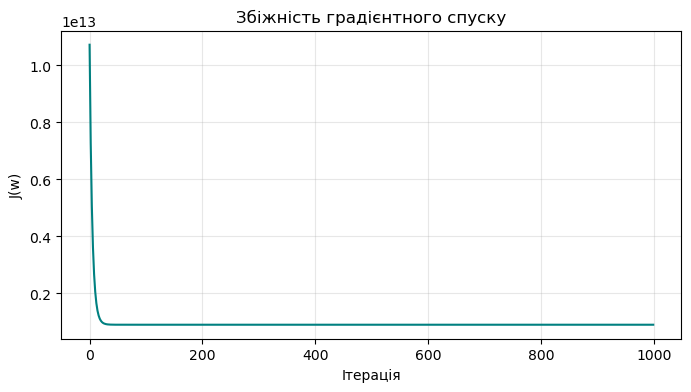

In [29]:
plt.figure(figsize=(8, 4))
plt.plot(history, color='teal')
plt.xlabel('Ітерація'); plt.ylabel('J(w)')
plt.title('Збіжність градієнтного спуску')
plt.grid(alpha=.3)
plt.show()

In [32]:
def to_original_scale(w_std, mu, sigma):
    w = w_std[1:] / sigma
    b = w_std[0] - np.sum(w_std[1:] * mu / sigma)
    return np.concatenate([[b], w])

w_gd = to_original_scale(w_gd_std, mu, sigma)
w_gd

array([-1.73171608e+05,  3.78762754e+02,  1.38604950e+06,  4.06820034e+05])

In [ ]:
# 5. Аналітичне рішення

In [33]:
X_orig = np.column_stack([np.ones(len(y)), X_raw])
w_analytic = np.linalg.solve(X_orig.T @ X_orig, X_orig.T @ y)
w_analytic

array([-1.73171608e+05,  3.78762754e+02,  1.38604950e+06,  4.06820034e+05])

In [ ]:
# 6. Перевірка спрогнозованих значень за допомогою LinearRegression та порівяння результатів

In [34]:
model = LinearRegression().fit(X_raw, y)
w_sklearn = np.concatenate([[model.intercept_], model.coef_])
w_sklearn

array([-1.73171608e+05,  3.78762754e+02,  1.38604950e+06,  4.06820034e+05])

In [35]:
names = ['intercept'] + features
cmp = pd.DataFrame({'Градієнтний спуск': w_gd, 'Аналітичне': w_analytic, 'sklearn': w_sklearn}, index=names)
cmp

,Градієнтний спуск,Аналітичне,sklearn
intercept,-1.731716e+05,-1.731716e+05,-1.731716e+05
area,3.787628e+02,3.787628e+02,3.787628e+02
bathrooms,1.386049e+06,1.386049e+06,1.386049e+06
bedrooms,4.068200e+05,4.068200e+05,4.068200e+05


In [36]:
pred_gd = X_orig @ w_gd
pred_an = X_orig @ w_analytic
pred_sk = model.predict(X_raw)

print('Макс. різниця параметрів (ГС vs аналітичне):', np.abs(w_gd - w_analytic).max())
print('Макс. різниця параметрів (аналітичне vs sklearn):', np.abs(w_analytic - w_sklearn).max())
print('Макс. різниця прогнозів (ГС vs sklearn):', np.abs(pred_gd - pred_sk).max())
print('Прогнози збігаються:', np.allclose(pred_gd, pred_sk, rtol=1e-6) and np.allclose(pred_an, pred_sk))

Макс. різниця параметрів (ГС vs аналітичне): 2.8230715543031693e-09
Макс. різниця параметрів (аналітичне vs sklearn): 6.548361852765083e-09
Макс. різниця прогнозів (ГС vs sklearn): 2.0489096641540527e-08
Прогнози збігаються: True


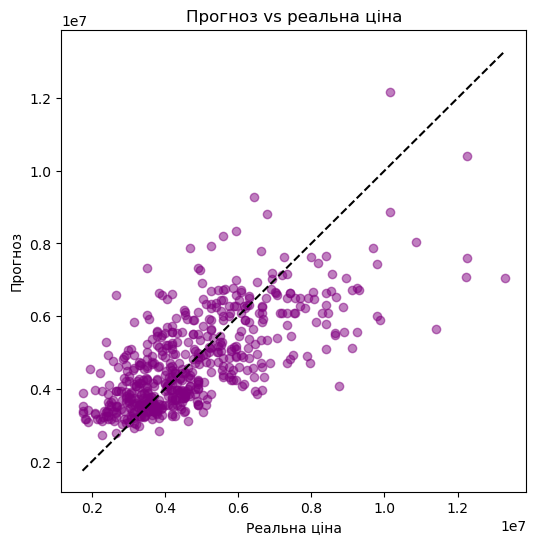

In [37]:
plt.figure(figsize=(6, 6))
plt.scatter(y, pred_sk, alpha=.5, color='purple')
lims = [y.min(), y.max()]
plt.plot(lims, lims, 'k--')
plt.xlabel('Реальна ціна'); plt.ylabel('Прогноз')
plt.title('Прогноз vs реальна ціна')
plt.show()